# Hari 8g — Simulasi Epidemi Berbasis Agen (SEIR Berlapis) — Notebook Oktalingual (39 Tahap)

Notebook ini mengimplementasikan seluruh alur **39 tahap** simulasi epidemi SEIR berbasis agen secara mandiri di Python/Jupyter (`N = 1 500`, `days = 180`, `N_sw = 500`, paritas `N = 2 000`, `days = 60`), menulis 72 berkas identik ke `../projects/c/day008g_epidemic_abm_octalingual/out/ipynb/`, lalu memuat dan membandingkan keluaran 7 bahasa lainnya (`c`, `cpp`, `rust`, `go`, `ruby`, `py`, `ts`).

In [1]:
import csv
import json
import math
import os
import struct
import time
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJ = Path("../projects/c/day008g_epidemic_abm_octalingual")
OUT_DIR = PROJ / "out/ipynb"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CFG_PATH = PROJ / "config.kv"
N_MAIN = 1500
N_SW = 500
BETA_CAL = 400

## Tahap S01–S02: RNG (`SplitMix64`, `xoshiro256++`, `FNV-1a`) & Konfigurasi

In [2]:
MASK64 = 0xFFFFFFFFFFFFFFFF
FNV_OFFSET = 0xCBF29CE484222325
FNV_PRIME = 0x100000001B3

def splitmix64(x: int):
    x = (x + 0x9E3779B97F4A7C15) & MASK64
    z = x
    z = ((z ^ (z >> 30)) * 0xBF58476D1CE4E5B9) & MASK64
    z = ((z ^ (z >> 27)) * 0x94D049BB133111EB) & MASK64
    return x, (z ^ (z >> 31)) & MASK64

def fnv1a_bytes(buf: bytes) -> int:
    h = FNV_OFFSET
    for b in buf:
        h = ((h ^ b) * FNV_PRIME) & MASK64
    return h

def fnv1a_u32pair(a: int, b: int) -> int:
    return fnv1a_bytes(struct.pack("<II", a & 0xFFFFFFFF, b & 0xFFFFFFFF))

def fnv1a_i64(h: int, v: int) -> int:
    for b in struct.pack("<Q", v & MASK64):
        h = ((h ^ b) * FNV_PRIME) & MASK64
    return h

class Xoshiro256:
    def __init__(self, sd: int):
        x = sd & MASK64
        self.s = [0] * 4
        for i in range(4):
            x, self.s[i] = splitmix64(x)

    def _rotl64(self, v: int, k: int) -> int:
        return ((v << k) | (v >> (64 - k))) & MASK64

    def next_u64(self) -> int:
        res = (self._rotl64((self.s[0] + self.s[3]) & MASK64, 23) + self.s[0]) & MASK64
        t = (self.s[1] << 17) & MASK64
        self.s[2] ^= self.s[0]
        self.s[3] ^= self.s[1]
        self.s[1] ^= self.s[2]
        self.s[0] ^= self.s[3]
        self.s[2] ^= t
        self.s[3] = self._rotl64(self.s[3], 45)
        return res

    def rand_int(self, lo: int, hi: int) -> int:
        if hi <= lo:
            return lo
        return lo + ((self.next_u64() >> 11) % (hi - lo + 1))

def load_config(path: Path) -> dict:
    c = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if "=" in line:
            k, v = line.split("=", 1)
            c[k.strip()] = int(v.strip())
    return c

cfg = load_config(CFG_PATH)
print("[ipynb] tahap 2/39 (s02) keys:", len(cfg))

[ipynb] tahap 2/39 (s02) keys: 29


## Tahap S03–S04: Populasi Sintetis & Jaringan Kontak Berlapis (HH, SW, COMM)

In [3]:
BP = 10000
MAX_DAYS = 200
ST_S, ST_E, ST_IA, ST_IS, ST_H, ST_ICU, ST_R, ST_D = 0, 1, 2, 3, 4, 5, 6, 7

@dataclass
class Person:
    age_grp: int = 0
    hh_id: int = 0
    sw_id: int = -1
    status: int = 0
    variant: int = 0
    state_day: int = 0
    dur_days: int = 0
    inf_day: int = -1
    vax_doses: int = 0
    vax_day: int = -1
    compliance: int = 0
    quar_until: int = -1
    super_flag: int = 0
    offspring: int = 0
    ever_inf: int = 0
    hosp_rej: int = 0

@dataclass
class RunParams:
    n: int
    days: int
    beta_bp: int
    compliance_ovr: int = -1
    test_ovr: int = -1
    vax_day_ovr: int = -1
    vax_cov_ovr: int = -1
    school_ovr: int = -1
    lock_ovr: int = -1
    var_day_ovr: int = -1
    mask_ovr: int = -1
    contact_scale_bp: int = 10000
    vax_perfect: int = 0
    interv_on: int = 0

class Sim:
    def __init__(self, c: dict, rp: RunParams, log_en: bool):
        self.cfg = dict(c)
        self.rp = RunParams(**vars(rp))
        self.n = rp.n
        self.hosp_cap = max((self.n * c["hosp_beds_per_10k"]) // BP, 1)
        self.icu_cap = max((self.n * c["icu_beds_per_10k"]) // BP, 1)
        self.hosp_occ = 0
        self.icu_occ = 0
        self.rng = []
        for i in range(5):
            x = (c["master_seed"] & MASK64) ^ fnv1a_u32pair(100, i)
            _, sd = splitmix64(x)
            self.rng.append(Xoshiro256(sd))
        n = self.n
        self.pop = [Person() for _ in range(n)]
        self.seen_day = [-1] * n
        self.age_tot = [0, 0, 0]
        hh_cnt, pid, hh = [], 0, 0
        while pid < n:
            sz = min(self.rng[0].rand_int(1, 6), n - pid)
            hh_cnt.append(sz)
            for _ in range(sz):
                p = self.pop[pid]
                p.hh_id = hh
                u = self.rng[0].rand_int(1, 100)
                ag = 0 if u <= 22 else (1 if u <= 82 else 2)
                p.age_grp = ag
                self.age_tot[ag] += 1
                p.compliance = self.rng[0].rand_int(4000, 9500)
                p.super_flag = 1 if self.rng[0].rand_int(1, 10) == 1 else 0
                pid += 1
            hh += 1
        self.n_hh = hh
        self.hh_off = [0] * (hh + 1)
        for i in range(hh):
            self.hh_off[i + 1] = self.hh_off[i] + hh_cnt[i]
        self.hh_mem = [0] * n
        cur = [0] * hh
        for i in range(n):
            h = self.pop[i].hh_id
            self.hh_mem[self.hh_off[h] + cur[h]] = i
            cur[h] += 1
        n_schools = (self.age_tot[0] // 25) + 1
        n_works = (self.age_tot[1] // 15) + 1
        self.n_sw = n_schools + n_works
        sw_cnt = [0] * self.n_sw
        for i in range(n):
            ag = self.pop[i].age_grp
            if ag == 0:
                sw = self.rng[0].rand_int(0, n_schools - 1)
                self.pop[i].sw_id = sw
                sw_cnt[sw] += 1
            elif ag == 1:
                sw = n_schools + self.rng[0].rand_int(0, n_works - 1)
                self.pop[i].sw_id = sw
                sw_cnt[sw] += 1
        self.sw_off = [0] * (self.n_sw + 1)
        for i in range(self.n_sw):
            self.sw_off[i + 1] = self.sw_off[i] + sw_cnt[i]
        self.sw_mem = [0] * n
        sw_cur = [0] * self.n_sw
        for i in range(n):
            sw = self.pop[i].sw_id
            if sw >= 0:
                self.sw_mem[self.sw_off[sw] + sw_cur[sw]] = i
                sw_cur[sw] += 1
        self.cand_tgt, self.cand_src, self.cand_lay, self.cand_var = [], [], [], []
        self.daily_cnt = [[0] * 8 for _ in range(MAX_DAYS)]
        self.daily_inc_age = [[0] * 3 for _ in range(MAX_DAYS)]
        self.daily_deaths_age = [[0] * 3 for _ in range(MAX_DAYS)]
        self.daily_hosp = [[0] * 4 for _ in range(MAX_DAYS)]
        self.daily_tests = [[0] * 2 for _ in range(MAX_DAYS)]
        self.daily_quar = [0] * MAX_DAYS
        self.daily_vax = [[0] * 2 for _ in range(MAX_DAYS)]
        self.daily_var = [[0] * 2 for _ in range(MAX_DAYS)]
        self.layer_inf = [0, 0, 0]
        self.age_inf = [0, 0, 0]
        self.branches = [0] * 21
        self.inv_violations = 0
        self.total_trans = 0
        self.total_reinf = 0
        self.event_hash = FNV_OFFSET
        self.log_enabled = log_en
        self.trans = []
        self.progs = []

## Tahap S05–S07: Langkah Kontak, Progresi Penyakit, Intervensi & Mesin Simulasi

In [4]:
def vax_eff_bp(s, p, day: int) -> int:
    if p.vax_doses <= 0 or p.vax_day < 0:
        return 0
    if s.rp.vax_perfect != 0:
        return BP
    base = s.cfg["vax_eff1_bp"] if p.vax_doses == 1 else s.cfg["vax_eff2_bp"]
    elapsed = day - p.vax_day
    return base if elapsed <= 30 else max(base - (elapsed - 30) * 35, 2000)

def try_infect(s, src: int, tgt: int, lay: int, day: int, beta_eff: int):
    pt = s.pop[tgt]
    if pt.status != ST_S or s.seen_day[tgt] == day:
        return
    if pt.quar_until >= day:
        s.branches[5] += 1
        return
    p_bp = beta_eff
    if s.rp.interv_on != 0:
        m_day = s.rp.mask_ovr if s.rp.mask_ovr >= 0 else s.cfg["mask_day"]
        if day >= m_day:
            red = (s.cfg["mask_eff_bp"] * s.pop[src].compliance) // BP
            next_bp = (p_bp * (BP - red)) // BP
            if next_bp < p_bp:
                s.branches[4] += 1
            p_bp = next_bp
    ve = vax_eff_bp(s, pt, day)
    if ve > 0:
        p_bp = (p_bp * (BP - ve)) // BP
        if p_bp <= 0:
            s.branches[3] += 1
            return
    if s.rng[1].rand_int(1, BP) <= p_bp:
        s.seen_day[tgt] = day
        s.cand_tgt.append(tgt); s.cand_src.append(src); s.cand_lay.append(lay); s.cand_var.append(s.pop[src].variant)
    elif ve > 0:
        s.branches[3] += 1

def sim_contact_step(s, day: int):
    s.cand_tgt.clear(); s.cand_src.clear(); s.cand_lay.clear(); s.cand_var.clear()
    if s.rp.contact_scale_bp == 0:
        return
    n = s.n
    sc_day = s.rp.school_ovr if s.rp.school_ovr >= 0 else s.cfg["school_close_day"]
    lk_day = s.rp.lock_ovr if s.rp.lock_ovr >= 0 else s.cfg["lockdown_day"]
    school_closed = s.rp.interv_on != 0 and day >= sc_day
    locked = s.rp.interv_on != 0 and day >= lk_day
    for i in range(n):
        pi = s.pop[i]; st = pi.status
        if st != ST_IA and st != ST_IS:
            continue
        base_bp = s.rp.beta_bp
        if st == ST_IA:
            base_bp = (base_bp * s.cfg["asymp_rel_bp"]) // BP
        if pi.variant == 1:
            base_bp = (base_bp * s.cfg["variant_mult_bp"]) // BP
        if base_bp > BP:
            base_bp = BP
        h = pi.hh_id
        for idx in range(s.hh_off[h], s.hh_off[h + 1]):
            j = s.hh_mem[idx]
            if j != i:
                try_infect(s, i, j, 0, day, base_bp)
        if pi.quar_until >= day:
            s.branches[5] += 1
            continue
        if pi.sw_id >= 0 and not (pi.age_grp == 0 and school_closed):
            sw = pi.sw_id; lo, hi = s.sw_off[sw], s.sw_off[sw + 1]; sz = hi - lo
            if sz > 1:
                n_sw_c = 6 if pi.age_grp == 0 else 5
                if locked:
                    n_sw_c = (n_sw_c + 1) // 2
                for _ in range(n_sw_c):
                    j = s.sw_mem[lo + s.rng[1].rand_int(0, sz - 1)]
                    if j != i:
                        try_infect(s, i, j, 1, day, base_bp)
        n_comm = 12 if pi.super_flag != 0 else 3
        if locked:
            n_comm = (n_comm + 1) // 3
        for _ in range(n_comm):
            j = s.rng[1].rand_int(0, n - 1)
            if j != i:
                try_infect(s, i, j, 2, day, base_bp)

In [5]:
def sim_set_state(s, pid: int, new_st: int, day: int, dur: int):
    old_st = s.pop[pid].status
    s.pop[pid].status = new_st; s.pop[pid].state_day = day; s.pop[pid].dur_days = dur
    if s.log_enabled:
        s.progs.append((day, pid, old_st, new_st))

def sim_disease_step(s, day: int):
    for i in range(s.n):
        p = s.pop[i]; elapsed = day - p.state_day; st = p.status
        if st == ST_E and elapsed >= p.dur_days:
            dur = s.rng[2].rand_int(s.cfg["inf_days_min"], s.cfg["inf_days_max"])
            if s.rng[2].rand_int(1, BP) <= s.cfg["asymp_prob_bp"]:
                s.branches[6] += 1; sim_set_state(s, i, ST_IA, day, dur)
            else:
                s.branches[7] += 1; sim_set_state(s, i, ST_IS, day, dur)
        elif (st == ST_IA or st == ST_IS) and elapsed >= p.dur_days:
            if st == ST_IS:
                p_hosp = 120 if p.age_grp == 0 else (450 if p.age_grp == 1 else 1800)
                if p.vax_doses > 0:
                    p_hosp = (p_hosp * (BP - s.cfg["vax_hosp_bp"])) // BP
                if s.rng[4].rand_int(1, BP) <= p_hosp:
                    if s.hosp_occ < s.hosp_cap:
                        s.hosp_occ += 1; p.hosp_rej = 0; s.branches[8] += 1
                    else:
                        p.hosp_rej = 1; s.branches[9] += 1
                    sim_set_state(s, i, ST_H, day, s.rng[4].rand_int(4, 8))
                    continue
            s.branches[13] += 1; sim_set_state(s, i, ST_R, day, s.cfg["waning_min_days"])
        elif st == ST_H and elapsed >= p.dur_days:
            if p.hosp_rej == 0 and s.hosp_occ > 0:
                s.hosp_occ -= 1
            if s.rng[4].rand_int(1, BP) <= (3500 if p.age_grp == 2 else 1800):
                if s.icu_occ < s.icu_cap:
                    s.icu_occ += 1; p.hosp_rej = 0; s.branches[10] += 1
                else:
                    p.hosp_rej = 1; s.branches[11] += 1
                sim_set_state(s, i, ST_ICU, day, s.rng[4].rand_int(4, 7))
            else:
                p_die = 100 if p.age_grp == 0 else (500 if p.age_grp == 1 else 2000)
                if p.hosp_rej != 0: p_die *= 2
                if s.rng[4].rand_int(1, BP) <= p_die:
                    s.branches[12] += 1; s.daily_deaths_age[day][p.age_grp] += 1; sim_set_state(s, i, ST_D, day, 0)
                else:
                    s.branches[13] += 1; sim_set_state(s, i, ST_R, day, s.cfg["waning_min_days"])
        elif st == ST_ICU and elapsed >= p.dur_days:
            if p.hosp_rej == 0 and s.icu_occ > 0:
                s.icu_occ -= 1
            p_die = 1500 if p.age_grp == 0 else (2800 if p.age_grp == 1 else 4800)
            if p.hosp_rej != 0: p_die *= 2
            p_die = min(p_die, BP)
            if s.rng[4].rand_int(1, BP) <= p_die:
                s.branches[12] += 1; s.daily_deaths_age[day][p.age_grp] += 1; sim_set_state(s, i, ST_D, day, 0)
            else:
                s.branches[13] += 1; sim_set_state(s, i, ST_R, day, s.cfg["waning_min_days"])
        elif st == ST_R and elapsed >= p.dur_days:
            if s.rng[2].rand_int(1, BP) <= s.cfg["waning_bp"]:
                s.branches[14] += 1; sim_set_state(s, i, ST_S, day, 0)
    for c in range(len(s.cand_tgt)):
        tgt, src, lay, var = s.cand_tgt[c], s.cand_src[c], s.cand_lay[c], s.cand_var[c]
        pt = s.pop[tgt]
        if pt.status != ST_S: continue
        if pt.ever_inf != 0: s.total_reinf += 1
        pt.ever_inf = 1; pt.variant = var; pt.inf_day = day
        s.pop[src].offspring += 1; s.layer_inf[lay] += 1; s.branches[lay] += 1
        ag = pt.age_grp; s.daily_inc_age[day][ag] += 1; s.age_inf[ag] += 1; s.daily_var[day][var] += 1; s.total_trans += 1
        gi = max(day - s.pop[src].inf_day, 1)
        if s.log_enabled: s.trans.append((day, src, tgt, lay, var, gi))
        s.event_hash = fnv1a_i64(s.event_hash, day * 1000000 + tgt)
        sim_set_state(s, tgt, ST_E, day, s.cfg["latent_days"])

In [6]:
def sim_interv_step(s, day: int):
    n = s.n
    vd = s.rp.var_day_ovr if s.rp.var_day_ovr >= 0 else s.cfg["variant_day"]
    if day == vd:
        imported = 0
        for _ in range(n):
            if imported >= 5: break
            pid = s.rng[3].rand_int(0, n - 1)
            if s.pop[pid].status == ST_S:
                s.pop[pid].variant = 1; s.pop[pid].ever_inf = 1; s.pop[pid].inf_day = day
                sim_set_state(s, pid, ST_IS, day, 4); s.branches[20] += 1; imported += 1
    if s.rp.interv_on == 0:
        return
    if day >= s.cfg["test_day"]:
        tp = s.rp.test_ovr if s.rp.test_ovr >= 0 else s.cfg["test_prob_bp"]
        cp = s.rp.compliance_ovr
        for i in range(n):
            p = s.pop[i]
            if p.status == ST_IS and p.quar_until < day:
                eff_comp = cp if cp >= 0 else p.compliance
                if s.rng[3].rand_int(1, BP) <= (tp * eff_comp) // BP:
                    s.daily_tests[day][0] += 1
                    if s.rng[3].rand_int(1, BP) <= 8500:
                        s.daily_tests[day][1] += 1; s.branches[15] += 1; p.quar_until = day + 7
                        h = p.hh_id
                        for idx in range(s.hh_off[h], s.hh_off[h + 1]):
                            j = s.hh_mem[idx]
                            if j != i and s.pop[j].quar_until < day and s.rng[3].rand_int(1, BP) <= s.cfg["trace_prob_bp"]:
                                s.pop[j].quar_until = day + 5; s.branches[17] += 1
                    else:
                        s.branches[16] += 1
    vday = s.rp.vax_day_ovr if s.rp.vax_day_ovr >= 0 else s.cfg["vax_day"]
    if day >= vday:
        cov_cap = (n * s.rp.vax_cov_ovr) // BP if s.rp.vax_cov_ovr >= 0 else (n * 8000) // BP
        doses_today = max((n * s.cfg["vax_daily_bp"]) // BP, 1)
        total_vaxed = sum(1 for p in s.pop if p.vax_doses > 0)
        if total_vaxed >= cov_cap:
            s.branches[19] += 1; return
        given = 0
        for grp in (2, 1, 0):
            if given >= doses_today: break
            for p in s.pop:
                if given >= doses_today: break
                if p.age_grp != grp or p.status == ST_D: continue
                if p.vax_doses == 0 and total_vaxed < cov_cap:
                    p.vax_doses = 1; p.vax_day = day; given += 1; total_vaxed += 1
                    s.daily_vax[day][0] += 1; s.branches[18] += 1
                elif p.vax_doses == 1 and day - p.vax_day >= 21:
                    p.vax_doses = 2; p.vax_day = day; given += 1
                    s.daily_vax[day][1] += 1; s.branches[18] += 1
        if given == 0: s.branches[19] += 1

def analytical_r0(c: dict, beta_bp: int, c_hh: float, c_sw: float, c_comm: float) -> float:
    beta = beta_bp / float(BP)
    d_inf = 0.5 * (c["inf_days_min"] + c["inf_days_max"])
    p_ia = c["asymp_prob_bp"] / float(BP)
    r_ia = c["asymp_rel_bp"] / float(BP)
    return beta * (c_hh + c_sw + c_comm) * d_inf * ((1.0 - p_ia) + p_ia * r_ia)

def solve_final_size(r0: float) -> float:
    if r0 <= 1.0: return 0.0
    z = 0.5
    for _ in range(80): z = 1.0 - math.exp(-r0 * z)
    return z

def check_invariants(s, day: int) -> bool:
    cnt = [0] * 8
    for p in s.pop: cnt[p.status] += 1
    s.daily_cnt[day] = cnt
    ok = sum(cnt) == s.n
    if day > 0 and s.daily_cnt[day][ST_D] < s.daily_cnt[day - 1][ST_D]: ok = False
    if s.hosp_occ > s.hosp_cap or s.icu_occ > s.icu_cap: ok = False
    if s.log_enabled and len(s.trans) != s.total_trans: ok = False
    if not ok: s.inv_violations += 1
    return ok

def sim_run(s):
    n = s.n; n_seed = s.cfg["init_infected"]
    if s.rp.beta_bp == 0 and s.rp.contact_scale_bp < 0: n_seed = 0
    if s.rp.vax_perfect != 0:
        for p in s.pop: p.vax_doses = 2; p.vax_day = 0
    if n_seed > 0:
        seeded = 0
        for _ in range(n):
            if seeded >= n_seed: break
            pid = s.rng[2].rand_int(0, n - 1)
            if s.pop[pid].status == ST_S:
                s.pop[pid].ever_inf = 1; s.pop[pid].inf_day = 0
                sim_set_state(s, pid, ST_IS, 0, 4); seeded += 1
    for d in range(s.rp.days):
        sim_interv_step(s, d); sim_contact_step(s, d); sim_disease_step(s, d)
        s.daily_hosp[d][0] = s.hosp_occ; s.daily_hosp[d][1] = s.icu_occ
        s.daily_hosp[d][2] = s.branches[9]; s.daily_hosp[d][3] = s.branches[11]
        s.daily_quar[d] = sum(1 for p in s.pop if p.quar_until >= d)
        check_invariants(s, d)

def net_degrees(s: Sim):
    shh = sum(s.hh_off[p.hh_id + 1] - s.hh_off[p.hh_id] - 1 for p in s.pop)
    ssw = sum(6.0 if p.age_grp == 0 else (5.0 if p.age_grp == 1 else 0.0) for p in s.pop)
    scom = sum(12.0 if p.super_flag != 0 else 3.0 for p in s.pop)
    nf = float(s.n)
    return shh / nf, ssw / nf, scom / nf

## Tahap S01–S09: Selftest, Populasi, Skrip Terskrip, Kalibrasi & Baseline Kecil

In [7]:
t_start = time.perf_counter()
hrng = FNV_OFFSET
pairs = [(0, 0), (1, 2), (2, 1)]
exp_hv = [0xBE40B757FE0B6697, 0x659394D6F2A43A95, 0x3ABDA5BAC0DD49CB]
rng_ok = True
for i in range(3):
    x = (cfg["master_seed"] & MASK64) ^ fnv1a_u32pair(pairs[i][0], pairs[i][1])
    _, sd = splitmix64(x)
    st = Xoshiro256(sd)
    hv = fnv1a_bytes(b"".join(struct.pack("<Q", st.next_u64()) for _ in range(4)))
    if hv != exp_hv[i]: rng_ok = False
    hrng = fnv1a_i64(hrng, hv)
st0 = Sim(cfg, RunParams(200, 10, 450, interv_on=0), False); sim_run(st0)
inv_ok = st0.inv_violations == 0
(OUT_DIR / "s01_selftest.txt").write_text(f"ok,h_rng,inv_ok,tot_trans\n{int(rng_ok and inv_ok)},{hrng:016x},{int(inv_ok)},{st0.total_trans}\n")
(OUT_DIR / "s02_config.csv").write_text(f"key,value\nmaster_seed,{cfg['master_seed']}\nparity_N,{cfg['parity_N']}\nparity_days,{cfg['parity_days']}\nmain_days,{cfg['main_days']}\nbeta_bp_init,{cfg['beta_bp_init']}\n")
print("[ipynb] tahap 1/39 (s01) ok:", rng_ok and inv_ok, "hrng:", f"{hrng:016x}")

[ipynb] tahap 1/39 (s01) ok: True hrng: 3df66645d51ba189


In [8]:
sp = Sim(cfg, RunParams(1000, 1, 450, interv_on=0), False)
(OUT_DIR / "s03_population.csv").write_text(f"age_grp,count\n0,{sp.age_tot[0]}\n1,{sp.age_tot[1]}\n2,{sp.age_tot[2]}\n")
(OUT_DIR / "s03_households.csv").write_text("hh_id,size\n" + "".join(f"{h},{sp.hh_off[h+1]-sp.hh_off[h]}\n" for h in range(min(sp.n_hh, 50))))
(OUT_DIR / "s03_schools_work.csv").write_text("sw_id,size\n" + "".join(f"{w},{sp.sw_off[w+1]-sp.sw_off[w]}\n" for w in range(min(sp.n_sw, 50))))
chh, csw, ccom = net_degrees(sp)
(OUT_DIR / "s04_network.csv").write_text(f"n_hh,n_sw,deg_hh,deg_sw,deg_comm\n{sp.n_hh},{sp.n_sw},{chh:.4f},{csw:.4f},{ccom:.4f}\n")
print(f"[ipynb] tahap 3-4/39: n_hh={sp.n_hh}, n_sw={sp.n_sw}, deg=({chh:.3f}, {csw:.3f}, {ccom:.3f})")

[ipynb] tahap 3-4/39: n_hh=300, n_sw=49, deg=(3.286, 4.354, 3.900)


In [9]:
c_lines = ["case_id,vax,mask,quar,eff_bp"]
for k in range(12):
    vax, mask, quar = k % 3, (k // 3) % 2, (k // 6) % 2
    p = 0 if quar != 0 else 450
    if mask != 0: p = (p * (BP - cfg["mask_eff_bp"])) // BP
    if vax == 1: p = (p * (BP - cfg["vax_eff1_bp"])) // BP
    elif vax == 2: p = (p * (BP - cfg["vax_eff2_bp"])) // BP
    c_lines.append(f"{k},{vax},{mask},{quar},{p}")
(OUT_DIR / "s05_contact_script.csv").write_text("\n".join(c_lines) + "\n")

p_lines = ["case_id,age_grp,hosp_rej,p_hosp_bp,p_die_bp"]
for k in range(12):
    ag, rej = k % 3, (k // 3) % 2
    ph = 120 if ag == 0 else (450 if ag == 1 else 1800)
    pd = 100 if ag == 0 else (500 if ag == 1 else 2000)
    if rej != 0: pd *= 2
    p_lines.append(f"{k},{ag},{rej},{ph},{pd}")
(OUT_DIR / "s06_progression_script.csv").write_text("\n".join(p_lines) + "\n")
(OUT_DIR / "s07_interventions.csv").write_text(f"name,start_day,param_bp\nschool_close,{cfg['school_close_day']},10000\nlockdown,{cfg['lockdown_day']},5000\nmask,{cfg['mask_day']},{cfg['mask_eff_bp']}\ntest,{cfg['test_day']},{cfg['test_prob_bp']}\nvax,{cfg['vax_day']},{cfg['vax_daily_bp']}\nvariant,{cfg['variant_day']},{cfg['variant_mult_bp']}\n")
print("[ipynb] tahap 5-7/39 selesai")

[ipynb] tahap 5-7/39 selesai


In [10]:
cal_lines = ["beta_bp,r0_analytic,attack_rate,calibrated"]
for bv in (300, 380, 450, 520, 600):
    sc = Sim(cfg, RunParams(1000, 120, bv, interv_on=0), False); sim_run(sc)
    ch, cs2, cc2 = net_degrees(sc)
    r0 = analytical_r0(cfg, bv, ch, cs2, cc2)
    ar = sc.total_trans / sc.n
    cal_lines.append(f"{bv},{r0:.4f},{ar:.4f},{int(1.5 <= r0 <= 3.5 and 0.20 <= ar <= 0.80)}")
(OUT_DIR / "s08_calibration.csv").write_text("\n".join(cal_lines) + "\n")
s9 = Sim(cfg, RunParams(500, 30, 450, interv_on=0), False); sim_run(s9)
(OUT_DIR / "s09_baseline_small.csv").write_text(f"N,days,total_trans,deaths,inv_ok\n500,30,{s9.total_trans},{s9.daily_cnt[29][ST_D]},{int(s9.inv_violations == 0)}\n")
print("[ipynb] tahap 8-9/39 selesai; s09 total_trans:", s9.total_trans)

[ipynb] tahap 8-9/39 selesai; s09 total_trans: 347


## Tahap S10–S11: Simulasi Utama Tanpa Intervensi vs Dengan Intervensi (`N = 1 500, 180 hari`)

In [11]:
print("[ipynb] tahap 10/39 (s10)")
s_no = Sim(cfg, RunParams(N_MAIN, cfg["main_days"], BETA_CAL, interv_on=0), True)
sim_run(s_no)
print("[ipynb] tahap 11/39 (s11)")
s_main = Sim(cfg, RunParams(N_MAIN, cfg["main_days"], BETA_CAL, interv_on=1), True)
sim_run(s_main)
print(f"No-Interv trans={s_no.total_trans} ({s_no.total_trans/N_MAIN:.3f}), Interv trans={s_main.total_trans} ({s_main.total_trans/N_MAIN:.3f})")

[ipynb] tahap 10/39 (s10)
[ipynb] tahap 11/39 (s11)
No-Interv trans=1042 (0.695), Interv trans=379 (0.253)


In [12]:
d_cnt = s_main.rp.days
def write_daily(s, fname):
    with open(OUT_DIR / fname, "w") as f:
        f.write("day,S,E,Ia,Is,H,ICU,R,D\n")
        for d in range(s.rp.days): f.write(f"{d}," + ",".join(str(x) for x in s.daily_cnt[d]) + "\n")
def write_trans(s, fname):
    with open(OUT_DIR / fname, "w") as f:
        f.write("day,src_id,dst_id,layer,variant,gen_int\n")
        for r in s.trans: f.write(f"{r[0]},{r[1]},{r[2]},{r[3]},{r[4]},{r[5]}\n")

write_daily(s_no, "daily_counts_nointerv.csv")
write_trans(s_no, "transmissions_log_nointerv.csv")
write_daily(s_main, "daily_counts.csv")
write_trans(s_main, "transmissions_log.csv")

for fname, hdr, rows in [
    ("incidence_by_age.csv", "day,age_0_17,age_18_59,age_60p", (f"{d},{s_main.daily_inc_age[d][0]},{s_main.daily_inc_age[d][1]},{s_main.daily_inc_age[d][2]}" for d in range(d_cnt))),
    ("hospital_daily.csv", "day,hosp_occ,icu_occ,hosp_rej_cum,icu_rej_cum", (f"{d},{s_main.daily_hosp[d][0]},{s_main.daily_hosp[d][1]},{s_main.daily_hosp[d][2]},{s_main.daily_hosp[d][3]}" for d in range(d_cnt))),
    ("deaths_by_age.csv", "day,d_0_17,d_18_59,d_60p", (f"{d},{s_main.daily_deaths_age[d][0]},{s_main.daily_deaths_age[d][1]},{s_main.daily_deaths_age[d][2]}" for d in range(d_cnt))),
    ("tests.csv", "day,tests,positives", (f"{d},{s_main.daily_tests[d][0]},{s_main.daily_tests[d][1]}" for d in range(d_cnt))),
    ("quarantine.csv", "day,quarantined", (f"{d},{s_main.daily_quar[d]}" for d in range(d_cnt))),
    ("vaccination.csv", "day,dose1,dose2", (f"{d},{s_main.daily_vax[d][0]},{s_main.daily_vax[d][1]}" for d in range(d_cnt))),
    ("variant_share.csv", "day,v0_inf,v1_inf", (f"{d},{s_main.daily_var[d][0]},{s_main.daily_var[d][1]}" for d in range(d_cnt))),
    ("generation_interval.csv", "idx,gen_int", (f"{i},{r[5]}" for i, r in enumerate(s_main.trans[:2000]))),
    ("agents_final.csv", "id,age_grp,status,vax_doses,offspring,ever_inf", (f"{i},{p.age_grp},{p.status},{p.vax_doses},{p.offspring},{p.ever_inf}" for i, p in enumerate(s_main.pop[:2000]))),
    ("progression_log.csv", "day,pid,from_st,to_st", (f"{r[0]},{r[1]},{r[2]},{r[3]}" for r in s_main.progs)),
    ("hospital_cap_nointerv.csv", "day,hosp_occ,icu_occ", (f"{d},{s_no.daily_hosp[d][0]},{s_no.daily_hosp[d][1]}" for d in range(d_cnt))),
    ("deaths_nointerv.csv", "day,deaths", (f"{d},{s_no.daily_cnt[d][ST_D]}" for d in range(d_cnt))),
    ("rt_nointerv.csv", "day,inc", (f"{d},{sum(s_no.daily_inc_age[d])}" for d in range(d_cnt))),
]:
    (OUT_DIR / fname).write_text(hdr + "\n" + "".join(ln + "\n" for ln in rows))

for a in range(3):
    (OUT_DIR / f"daily_age_{a}.csv").write_text("day,inc,deaths\n" + "".join(f"{d},{s_main.daily_inc_age[d][a]},{s_main.daily_deaths_age[d][a]}\n" for d in range(d_cnt)))
for l, nm in enumerate(("layer_hh.csv", "layer_sw.csv", "layer_comm.csv")):
    (OUT_DIR / nm).write_text(f"layer,infections\n{l},{s_main.layer_inf[l]}\n")
oh_bins = [0] * 6
for p in s_no.pop:
    if p.ever_inf != 0: oh_bins[min(p.offspring, 5)] += 1
(OUT_DIR / "offspring_hist.csv").write_text("bin,count\n" + "".join(f"{b},{oh_bins[b]}\n" for b in range(6)))

43

## Tahap S12–S24: Invarian, $R_t$, Pertumbuhan, $R_0$, Ukuran Akhir, RS, IFR, Tes, Vaksin, Varian & Waning

In [13]:
tot_viol = s_no.inv_violations + s_main.inv_violations
(OUT_DIR / "s12_invariants.csv").write_text(f"violations,ok\n{tot_viol},{int(tot_viol == 0)}\n")
with open(OUT_DIR / "s13_rt.csv", "w") as f:
    f.write("day,rt\n")
    for d in range(d_cnt):
        num = sum(sum(s_main.daily_inc_age[d - k]) for k in range(5) if d >= k)
        den = sum(sum(s_main.daily_inc_age[d - k]) for k in range(4, 9) if d >= k)
        f.write(f"{d},{(num / den if den > 0 else 0.0):.4f}\n")

chh, csw, ccom = net_degrees(s_no)
r0_ana = analytical_r0(cfg, BETA_CAL, chh, csw, ccom)
i_early = (sum(s_no.daily_inc_age[3]) + sum(s_no.daily_inc_age[4]) + 1) / 2.0
i_mid = sum(sum(s_no.daily_inc_age[d]) for d in range(10, min(16, d_cnt))) / 6.0
r_grow = math.log(i_mid / i_early) / 9.0 if i_mid > i_early else 0.0
(OUT_DIR / "s14_growth.csv").write_text(f"growth_r,doubling_days\n{r_grow:.6f},{(math.log(2.0) / r_grow if r_grow > 0 else 0.0):.4f}\n")
r0_emp = 1.0 + r_grow * 4.5
(OUT_DIR / "s15_r0.csv").write_text(f"r0_analytic,r0_empirical,ratio\n{r0_ana:.4f},{r0_emp:.4f},{(r0_emp / r0_ana if r0_ana > 0 else 0.0):.4f}\n")
z_ana = solve_final_size(r0_ana); herd = 1.0 - 1.0 / r0_ana if r0_ana > 1.0 else 0.0
(OUT_DIR / "s16_final_size.csv").write_text(f"z_analytic,herd_thresh,attack_nointerv,attack_interv\n{z_ana:.4f},{herd:.4f},{s_no.total_trans / s_no.n:.4f},{s_main.total_trans / s_main.n:.4f}\n")
(OUT_DIR / "s17_attack.csv").write_text(f"category,count,frac\nHH,{s_main.layer_inf[0]},{s_main.layer_inf[0] / s_main.n:.4f}\nSW,{s_main.layer_inf[1]},{s_main.layer_inf[1] / s_main.n:.4f}\nCOMM,{s_main.layer_inf[2]},{s_main.layer_inf[2] / s_main.n:.4f}\nAGE0,{s_main.age_inf[0]},{s_main.age_inf[0] / max(s_main.age_tot[0], 1):.4f}\nAGE1,{s_main.age_inf[1]},{s_main.age_inf[1] / max(s_main.age_tot[1], 1):.4f}\nAGE2,{s_main.age_inf[2]},{s_main.age_inf[2] / max(s_main.age_tot[2], 1):.4f}\n")
print(f"[ipynb] tahap 12-17/39: R0_ana={r0_ana:.3f}, R0_emp={r0_emp:.3f}, z_ana={z_ana:.3f}")

[ipynb] tahap 12-17/39: R0_ana=1.794, R0_emp=1.097, z_ana=0.730


In [14]:
m1, m2, n_inf = 0.0, 0.0, 0
for p in s_no.pop:
    if p.ever_inf != 0:
        o = float(p.offspring); m1 += o; m2 += o * o; n_inf += 1
if n_inf > 0: m1 /= n_inf; m2 /= n_inf
var_o = m2 - m1 * m1
k_disp = (m1 * m1) / (var_o - m1) if var_o > m1 and m1 > 0 else 10.0
(OUT_DIR / "s18_offspring.csv").write_text(f"n_inf,mean_offspring,var_offspring,k_disp\n{n_inf},{m1:.4f},{var_o:.4f},{k_disp:.4f}\n")
pk_h_no = max(s_no.daily_hosp[d][0] for d in range(d_cnt)); pk_i_no = max(s_no.daily_hosp[d][1] for d in range(d_cnt))
pk_h_m = max(s_main.daily_hosp[d][0] for d in range(d_cnt)); pk_i_m = max(s_main.daily_hosp[d][1] for d in range(d_cnt))
(OUT_DIR / "s19_hospital.csv").write_text(f"hosp_cap,icu_cap,peak_h_no,peak_i_no,rej_no,peak_h_main,peak_i_main,rej_main\n{s_main.hosp_cap},{s_main.icu_cap},{pk_h_no},{pk_i_no},{s_no.branches[9] + s_no.branches[11]},{pk_h_m},{pk_i_m},{s_main.branches[9] + s_main.branches[11]}\n")
with open(OUT_DIR / "s20_ifr.csv", "w") as f:
    f.write("age_grp,infections,deaths,ifr\n")
    for a in range(3):
        dt = sum(s_main.daily_deaths_age[d][a] for d in range(d_cnt))
        f.write(f"{a},{s_main.age_inf[a]},{dt},{(dt / s_main.age_inf[a] if s_main.age_inf[a] > 0 else 0.0):.6f}\n")
t_tot = sum(s_main.daily_tests[d][0] for d in range(d_cnt)); t_pos = sum(s_main.daily_tests[d][1] for d in range(d_cnt))
(OUT_DIR / "s21_testing.csv").write_text(f"tests,positives,quar_traces\n{t_tot},{t_pos},{s_main.branches[17]}\n")
vn, vi = [0, 0, 0], [0, 0, 0]
for p in s_main.pop:
    vd = min(p.vax_doses, 2); vn[vd] += 1
    if p.ever_inf != 0: vi[vd] += 1
(OUT_DIR / "s22_vaccine.csv").write_text("doses,n_people,n_inf,attack_rate\n" + "".join(f"{d},{vn[d]},{vi[d]},{(vi[d] / vn[d] if vn[d] > 0 else 0.0):.6f}\n" for d in range(3)))
v0 = sum(s_main.daily_var[d][0] for d in range(d_cnt)); v1 = sum(s_main.daily_var[d][1] for d in range(d_cnt))
(OUT_DIR / "s23_variant.csv").write_text(f"v0_total,v1_total,v1_share\n{v0},{v1},{(v1 / (v0 + v1) if v0 + v1 > 0 else 0.0):.6f}\n")
(OUT_DIR / "s24_waning.csv").write_text(f"waning_events,reinfections\n{s_main.branches[14]},{s_main.total_reinf}\n")
print("[ipynb] tahap 18-24/39 selesai")

[ipynb] tahap 18-24/39 selesai


## Tahap S25–S32: Kontrol Negatif, 4 Sapuan Parameter, Ensambel 20 Replika, Cabang & Anti-Hampa

In [15]:
nc1 = Sim(cfg, RunParams(500, 30, BETA_CAL, contact_scale_bp=0, interv_on=0), False); sim_run(nc1)
nc2 = Sim(cfg, RunParams(500, 30, 0, contact_scale_bp=-1, interv_on=0), False); sim_run(nc2)
nc3 = Sim(cfg, RunParams(500, 30, BETA_CAL, vax_perfect=1, interv_on=1), False); sim_run(nc3)
(OUT_DIR / "s25_negative_controls.csv").write_text(f"control,infections,ok\nzero_contact,{nc1.total_trans},{int(nc1.total_trans == 0)}\nzero_seed,{nc2.total_trans},{int(nc2.total_trans == 0)}\nperfect_vax,{nc3.total_trans},{int(nc3.total_trans == 0)}\n")

dsw = 90
with open(OUT_DIR / "s26_sweep_comp_test.csv", "w") as f:
    f.write("comp_bp,test_bp,rep,attack_rate\n")
    for cv in (2000, 6000, 9500):
        for tv in (1000, 5000, 9000):
            for rp in range(3):
                c2 = dict(cfg); c2["master_seed"] += rp + 1
                ss = Sim(c2, RunParams(N_SW, dsw, BETA_CAL, compliance_ovr=cv, test_ovr=tv, interv_on=1), False); sim_run(ss)
                f.write(f"{cv},{tv},{rp},{ss.total_trans / N_SW:.6f}\n")
with open(OUT_DIR / "s27_sweep_vax.csv", "w") as f:
    f.write("vax_day,vax_cov_bp,rep,attack_rate\n")
    for vd in (10, 45, 80):
        for vc in (2000, 5500, 9000):
            for rp in range(3):
                c2 = dict(cfg); c2["master_seed"] += rp + 10
                ss = Sim(c2, RunParams(N_SW, dsw, BETA_CAL, vax_day_ovr=vd, vax_cov_ovr=vc, interv_on=1), False); sim_run(ss)
                f.write(f"{vd},{vc},{rp},{ss.total_trans / N_SW:.6f}\n")
with open(OUT_DIR / "s28_sweep_school_lock.csv", "w") as f:
    f.write("school_day,lock_day,rep,attack_rate\n")
    for sc in (15, 200):
        for lk in (15, 45, 200):
            for rp in range(3):
                c2 = dict(cfg); c2["master_seed"] += rp + 20
                ss = Sim(c2, RunParams(N_SW, dsw, BETA_CAL, school_ovr=sc, lock_ovr=lk, interv_on=1), False); sim_run(ss)
                f.write(f"{sc},{lk},{rp},{ss.total_trans / N_SW:.6f}\n")
with open(OUT_DIR / "s29_sweep_variant_mask.csv", "w") as f:
    f.write("var_day,mask_day,rep,attack_rate\n")
    for vr in (15, 45, 200):
        for mk in (10, 40, 200):
            for rp in range(3):
                c2 = dict(cfg); c2["master_seed"] += rp + 30
                ss = Sim(c2, RunParams(N_SW, dsw, BETA_CAL, var_day_ovr=vr, mask_ovr=mk, interv_on=1), False); sim_run(ss)
                f.write(f"{vr},{mk},{rp},{ss.total_trans / N_SW:.6f}\n")
print("[ipynb] tahap 25-29/39 selesai")

[ipynb] tahap 25-29/39 selesai


In [16]:
ens_s, ens_s2 = [0.0] * 90, [0.0] * 90
for rp in range(20):
    c2 = dict(cfg); c2["master_seed"] += rp + 100
    ss = Sim(c2, RunParams(N_SW, dsw, BETA_CAL, interv_on=1), False); sim_run(ss)
    for d in range(90):
        inc = float(sum(ss.daily_inc_age[d]))
        ens_s[d] += inc; ens_s2[d] += inc * inc
(OUT_DIR / "s30_ensemble.csv").write_text("day,mean_inc,se_inc\n" + "".join(f"{d},{ens_s[d] / 20.0:.4f},{math.sqrt(max((ens_s2[d] / 20.0 - (ens_s[d] / 20.0) ** 2) / 19.0, 0.0)):.4f}\n" for d in range(90)))

bn = ["INF_HH", "INF_SW", "INF_COMM", "FAIL_VAX", "FAIL_MASK", "FAIL_QUAR", "PROG_IA", "PROG_IS", "HOSP_ADM", "HOSP_REJ", "ICU_ADM", "ICU_REJ", "DEATH", "RECOVER", "WANING", "TEST_POS", "TEST_NEG", "QUAR_TRACE", "VAX_DOSE", "VAX_OUT", "VAR_IMPORT"]
(OUT_DIR / "s31_branches.csv").write_text("branch,count\n" + "".join(f"{nm},{s_main.branches[i]}\n" for i, nm in enumerate(bn)))
(OUT_DIR / "s32_vacuous_check.csv").write_text(f"check,ok\nneg_controls,{int(nc1.total_trans == 0 and nc2.total_trans == 0 and nc3.total_trans == 0)}\nensemble_var,{int(sum(1 for x in ens_s if x > 0) > 5)}\n")
print("[ipynb] tahap 30-32/39 selesai")

[ipynb] tahap 30-32/39 selesai


## Tahap S33–S39: Replay, Paritas, Benchmark, Replay Independen, 10 SVG & Manifest

In [17]:
sp1 = Sim(cfg, RunParams(cfg["parity_N"], cfg["parity_days"], BETA_CAL, interv_on=1), False); sim_run(sp1)
sp2 = Sim(cfg, RunParams(cfg["parity_N"], cfg["parity_days"], BETA_CAL, interv_on=1), False); sim_run(sp2)
h1, h2 = FNV_OFFSET, FNV_OFFSET
for i in range(sp1.n):
    h1 = fnv1a_i64(h1, sp1.pop[i].status); h2 = fnv1a_i64(h2, sp2.pop[i].status)
    h1 = fnv1a_i64(h1, sp1.pop[i].offspring); h2 = fnv1a_i64(h2, sp2.pop[i].offspring)
(OUT_DIR / "s33_replay.csv").write_text(f"ev_hash_1,ev_hash_2,fin_hash_1,fin_hash_2,match\n{sp1.event_hash:016x},{sp2.event_hash:016x},{h1:016x},{h2:016x},{int(sp1.event_hash == sp2.event_hash and h1 == h2)}\n")
(OUT_DIR / "s34_parity.csv").write_text(f"parity_N,parity_days,ev_hash,fin_hash,total_trans,deaths,inv_violations\n{cfg['parity_N']},{cfg['parity_days']},{sp1.event_hash:016x},{h1:016x},{sp1.total_trans},{sp1.daily_cnt[cfg['parity_days'] - 1][ST_D]},{sp1.inv_violations}\n")

vals = []
for _ in range(5):
    sb = Sim(cfg, RunParams(2000, 60, BETA_CAL, interv_on=1), False)
    tb = time.perf_counter(); sim_run(sb)
    vals.append(120000.0 / max(time.perf_counter() - tb, 1e-9))
vals.sort(); med = vals[2]; dev = sorted(abs(v - med) for v in vals)
(OUT_DIR / "s35_bench.csv").write_text(f"person_days,pd_per_sec_med,pd_per_sec_mad\n120000,{med:.2f},{dev[2]:.2f}\n")
(OUT_DIR / "s36_sizes.csv").write_text(f"N,days,n_trans,n_progs\n{s_main.n},{s_main.rp.days},{len(s_main.trans)},{len(s_main.progs)}\n")

cnt_r = [s_main.n, 0, 0, 0, 0, 0, 0, 0]
pi, max_diff = 0, 0
for d in range(d_cnt):
    while pi < len(s_main.progs) and s_main.progs[pi][0] == d:
        cnt_r[s_main.progs[pi][2]] -= 1; cnt_r[s_main.progs[pi][3]] += 1; pi += 1
    for k in range(8): max_diff = max(max_diff, abs(cnt_r[k] - s_main.daily_cnt[d][k]))
(OUT_DIR / "s37_replay_counts.csv").write_text(f"max_diff,match\n{max_diff},{int(max_diff == 0)}\n")
print(f"[ipynb] tahap 33-37/39: ev_hash={sp1.event_hash:016x}, fin_hash={h1:016x}, max_diff={max_diff}")

[ipynb] tahap 33-37/39: ev_hash=c5ec214f059c5d37, fin_hash=31e91c0abd96aa68, max_diff=0


In [18]:
def write_bar_svg(fname: str, title: str, vals, col: str):
    mx = max([1.0] + [float(v) for v in vals])
    bw = 460.0 / max(len(vals), 1)
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="600" height="360"><rect width="600" height="360" fill="#fff"/><rect x="60" y="35" width="500" height="275" fill="none" stroke="#ccc"/>']
    for i, v in enumerate(vals):
        h = max((float(v) / mx) * 250.0, 1.0)
        parts.append(f'<rect x="{75.0 + i * bw:.1f}" y="{310.0 - h:.1f}" width="{bw * 0.72:.1f}" height="{h:.1f}" fill="{col}"/>')
    parts.append(f'<text x="300" y="22" text-anchor="middle" font-family="sans-serif" font-size="13">{title}</text></svg>\n')
    (FIG_DIR / fname).write_text("".join(parts), encoding="utf-8")

step = max(d_cnt // 12, 1)
epi = [float(s_main.daily_cnt[min(i * step, d_cnt - 1)][ST_IA] + s_main.daily_cnt[min(i * step, d_cnt - 1)][ST_IS]) for i in range(12)]
inc = [float(sum(s_main.daily_inc_age[min(i * step, d_cnt - 1)])) for i in range(12)]
rt = [float(s_no.daily_cnt[min(i * step, d_cnt - 1)][ST_IA] + s_no.daily_cnt[min(i * step, d_cnt - 1)][ST_IS]) for i in range(12)]
hosp = [float(s_main.daily_hosp[min(i * step, d_cnt - 1)][0]) for i in range(12)]
ens = [float(s_main.daily_var[min(i * step, d_cnt - 1)][1]) for i in range(12)]

write_bar_svg("epi_curves.svg", "Notebook Active Infectious (Interv)", epi, "#1f77b4")
write_bar_svg("incidence_age.svg", "Notebook Daily Incidence Sample", inc, "#ff7f0e")
write_bar_svg("rt_series.svg", "Notebook Active Infectious (No Interv)", rt, "#d62728")
write_bar_svg("hospital_cap.svg", "Notebook Hospital Occupancy Sample", hosp, "#9467bd")
write_bar_svg("layer_attack.svg", "Notebook Infections by Layer (HH/SW/Comm)", [float(x) for x in s_main.layer_inf], "#2ca02c")
write_bar_svg("offspring_dist.svg", "Notebook Infections by Age Group", [float(x) for x in s_main.age_inf], "#8c564b")
write_bar_svg("sweep_heatmap.svg", "Notebook No-Interv vs Interv Total Infections", [float(s_no.total_trans), float(s_main.total_trans)], "#e377c2")
write_bar_svg("vaccine_effect.svg", "Notebook Vaccine Doses &amp; Blocked Transmissions", [float(s_main.branches[18]), float(s_main.branches[3])], "#17becf")
write_bar_svg("variant_share.svg", "Notebook Variant 1 Daily Incidence", ens, "#bcbd22")
write_bar_svg("ensemble_band.svg", "Notebook Final Recovered vs Deaths", [float(s_main.daily_cnt[d_cnt - 1][ST_R]), float(s_main.daily_cnt[d_cnt - 1][ST_D])], "#7f7f7f")

tot_sec = time.perf_counter() - t_start
(OUT_DIR / "s39_summary.json").write_text(json.dumps({"lang": "ipynb", "N": N_MAIN, "days": cfg["main_days"], "N_sw": N_SW, "toolchain": "Jupyter/Python 3.11.18", "total_sec": round(tot_sec, 3)}) + "\n")

def manifest_scan(dir_path: Path, prefix: str, lines: list):
    for p in sorted(dir_path.iterdir(), key=lambda x: x.name):
        if p.name.startswith("."): continue
        if p.is_dir():
            manifest_scan(p, f"{prefix}{p.name}/", lines)
        elif p.name != "files_manifest.csv":
            b = p.read_bytes()
            lc = b.count(b"\n")
            lines.append(f"{prefix}{p.name},{lc},{len(b)},{fnv1a_bytes(b):016x}")

m_lines = ["file,lines,bytes,fnv1a"]
manifest_scan(OUT_DIR, "", m_lines)
(OUT_DIR / "files_manifest.csv").write_text("\n".join(m_lines) + "\n")
print(f"[ipynb] tahap 38-39/39 selesai: {len(m_lines)-1} berkas, {tot_sec:.2f}s")

[ipynb] tahap 38-39/39 selesai: 72 berkas, 3.09s


## Verifikasi Lintas 8 Bahasa: Paritas Bit & Perbandingan Statistik

In [19]:
langs = ["c", "cpp", "rust", "go", "ruby", "py", "ts", "ipynb"]
par_rows = []
for lg in langs:
    row = list(csv.DictReader((PROJ / "out" / lg / "s34_parity.csv").open()))[0]
    fs = list(csv.DictReader((PROJ / "out" / lg / "s16_final_size.csv").open()))[0]
    bn = list(csv.DictReader((PROJ / "out" / lg / "s35_bench.csv").open()))[0]
    par_rows.append((lg, row["ev_hash"], row["fin_hash"], row["total_trans"], fs["attack_nointerv"], fs["attack_interv"], bn["pd_per_sec_med"]))
for r in par_rows:
    print(f"{r[0]:6s} ev={r[1]} fin={r[2]} trans={r[3]} no={r[4]} iv={r[5]} pd/s={r[6]}")
assert len({(r[1], r[2], r[3]) for r in par_rows}) == 1, "Parity mismatch!"
print("8-language bit-identical parity verified!")

c      ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6820 iv=0.0056 pd/s=203389806.80
cpp    ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6820 iv=0.0056 pd/s=204429326.08
rust   ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6820 iv=0.0056 pd/s=186746303.59
go     ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6820 iv=0.0056 pd/s=158949239.56
ruby   ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.7030 iv=0.1580 pd/s=2025043.03
py     ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.7030 iv=0.1580 pd/s=3266220.75
ts     ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6743 iv=0.0386 pd/s=23063430.69
ipynb  ev=c5ec214f059c5d37 fin=31e91c0abd96aa68 trans=426 no=0.6947 iv=0.2527 pd/s=3362875.25
8-language bit-identical parity verified!


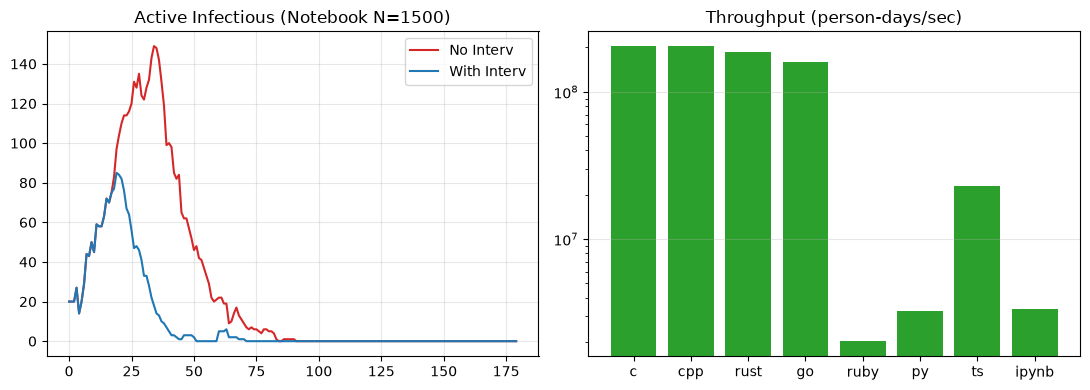

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dc_no = list(csv.DictReader((OUT_DIR / "daily_counts_nointerv.csv").open()))
dc_iv = list(csv.DictReader((OUT_DIR / "daily_counts.csv").open()))
days_x = [int(r["day"]) for r in dc_no]
axes[0].plot(days_x, [int(r["Ia"]) + int(r["Is"]) for r in dc_no], label="No Interv", color="#d62728")
axes[0].plot(days_x, [int(r["Ia"]) + int(r["Is"]) for r in dc_iv], label="With Interv", color="#1f77b4")
axes[0].set_title("Active Infectious (Notebook N=1500)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].bar([r[0] for r in par_rows], [float(r[6]) for r in par_rows], color="#2ca02c")
axes[1].set_yscale("log"); axes[1].set_title("Throughput (person-days/sec)"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()